# Model Results: Imbalance Strategy and Ensemble Comparison

after running `python train.py --data data/raw/creditcard.csv` from the repository root

In [13]:
from pathlib import Path
import json, math
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import precision_recall_curve, ConfusionMatrixDisplay
sns.set_theme(style='whitegrid')
root_candidates = [Path.cwd(), Path.cwd().parent]
ROOT = next((p for p in root_candidates if (p/'reports/model_comparison.csv').exists()), None)
if ROOT is None: raise FileNotFoundError('Run train.py first; reports/model_comparison.csv is missing.')
metrics = pd.read_csv(ROOT/'reports/model_comparison.csv')
pred = pd.read_csv(ROOT/'reports/holdout_transactions.csv')
meta = json.loads((ROOT/'reports/run_metadata.json').read_text(encoding='utf-8'))
print('Holdout class counts (untouched):', meta['holdout_class_counts_untouched'])
print('Models fit:', metrics['model'].unique().tolist())
metrics.head()

Holdout class counts (untouched): {'0': 56672, '1': 74}
Models fit: ['Random Forest + SMOTE (bagging)', 'Random Forest + class weights (bagging)', 'XGBoost + SMOTE (boosting)', 'XGBoost + class weights (boosting)']


,model,alert_budget_pct,alerts_reviewed,holdout_transactions,holdout_fraud,fraud_caught,recall_at_budget_pct,precision_at_budget_pct,accuracy_pct,f1_at_budget_pct,false_alerts,missed_fraud,average_precision,roc_auc,score_cutoff
0,Random Forest + SMOTE (bagging),0.5,284,56746,74,64,86.486486,22.535211,99.594685,35.754190,220,10,0.815484,0.988015,0.073952
1,Random Forest + SMOTE (bagging),1.0,568,56746,74,65,87.837838,11.443662,99.097734,20.249221,503,9,0.815484,0.988015,0.046381
2,Random Forest + class weights (bagging),0.5,284,56746,74,64,86.486486,22.535211,99.594685,35.754190,220,10,0.814953,0.975112,0.014273
3,Random Forest + class weights (bagging),1.0,568,56746,74,66,89.189189,11.619718,99.101258,20.560748,502,8,0.814953,0.975112,0.008561
4,XGBoost + SMOTE (boosting),0.5,284,56746,74,60,81.081081,21.126761,99.580587,33.519553,224,14,0.792667,0.984826,0.089386


## Metrics at equal review capacity

Recall at budget asks how much labeled fraud is inside the top-ranked alert slots. Precision at budget is the share of reviewed cases that have a fraud label. Average precision summarizes the precision-recall curve. A 99.8%+ accuracy score would mostly reflect the legitimate majority, so it is not the headline metric.

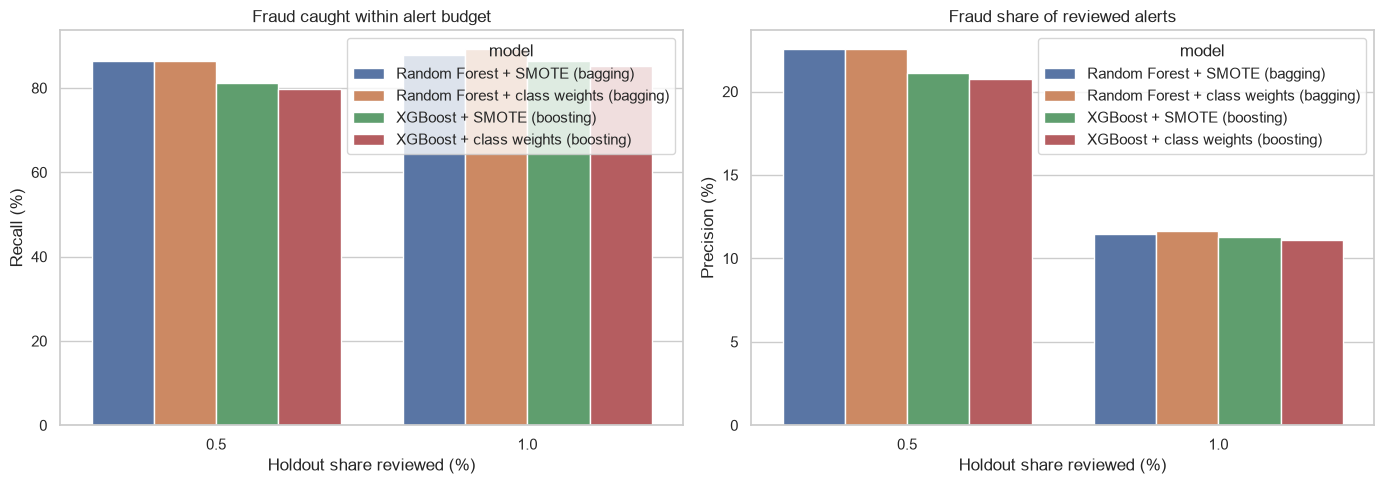

In [14]:
fig, axes = plt.subplots(1,2,figsize=(14,5))
sns.barplot(data=metrics, x='alert_budget_pct', y='recall_at_budget_pct', hue='model', ax=axes[0])
axes[0].set_title('Fraud caught within alert budget'); axes[0].set_xlabel('Holdout share reviewed (%)'); axes[0].set_ylabel('Recall (%)')
sns.barplot(data=metrics, x='alert_budget_pct', y='precision_at_budget_pct', hue='model', ax=axes[1])
axes[1].set_title('Fraud share of reviewed alerts'); axes[1].set_xlabel('Holdout share reviewed (%)'); axes[1].set_ylabel('Precision (%)')
plt.tight_layout(); plt.show()

In [15]:
display(metrics[['model','alert_budget_pct','alerts_reviewed','holdout_fraud','fraud_caught','accuracy_pct','precision_at_budget_pct','recall_at_budget_pct','f1_at_budget_pct','false_alerts','missed_fraud','average_precision','roc_auc']].sort_values(['alert_budget_pct','average_precision'], ascending=[True,False]).round(4))

,model,alert_budget_pct,alerts_reviewed,holdout_fraud,fraud_caught,accuracy_pct,precision_at_budget_pct,recall_at_budget_pct,f1_at_budget_pct,false_alerts,missed_fraud,average_precision,roc_auc
0,Random Forest + SMOTE (bagging),0.5,284,74,64,99.5947,22.5352,86.4865,35.7542,220,10,0.8155,0.9880
2,Random Forest + class weights (bagging),0.5,284,74,64,99.5947,22.5352,86.4865,35.7542,220,10,0.8150,0.9751
4,XGBoost + SMOTE (boosting),0.5,284,74,60,99.5806,21.1268,81.0811,33.5196,224,14,0.7927,0.9848
6,XGBoost + class weights (boosting),0.5,284,74,59,99.5771,20.7746,79.7297,32.9609,225,15,0.7839,0.9869
1,Random Forest + SMOTE (bagging),1.0,568,74,65,99.0977,11.4437,87.8378,20.2492,503,9,0.8155,0.9880
3,Random Forest + class weights (bagging),1.0,568,74,66,99.1013,11.6197,89.1892,20.5607,502,8,0.8150,0.9751
5,XGBoost + SMOTE (boosting),1.0,568,74,64,99.0942,11.2676,86.4865,19.9377,504,10,0.7927,0.9848
7,XGBoost + class weights (boosting),1.0,568,74,63,99.0907,11.0915,85.1351,19.6262,505,11,0.7839,0.9869


## Precision-recall curves

These curves use the untouched chronological holdout. Average precision can be compared across models, but always report the holdout fraud count and class prevalence beside it.

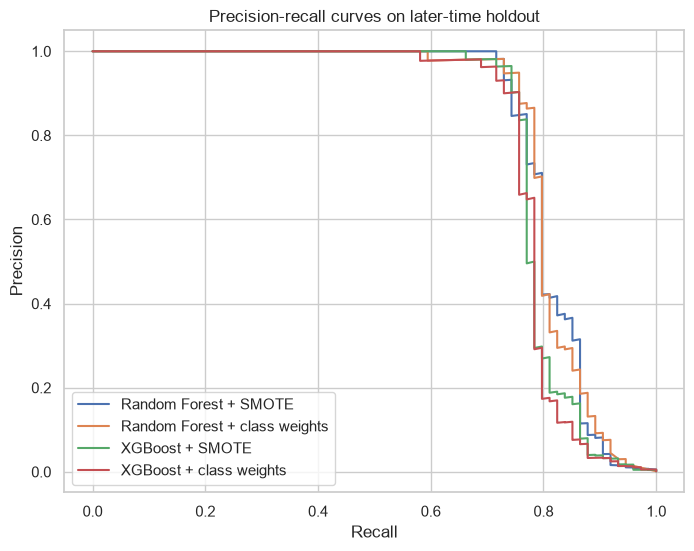

In [16]:
score_names = {'rf_smote':'Random Forest + SMOTE','rf_weighted':'Random Forest + class weights','xgb_smote':'XGBoost + SMOTE','xgb_weighted':'XGBoost + class weights'}
y_true = pred['Class'].astype(int).to_numpy()
plt.figure(figsize=(8,6))
for key, label in score_names.items():
    precision, recall, _ = precision_recall_curve(y_true, pred[f'score_{key}'])
    plt.plot(recall, precision, label=label)
plt.xlabel('Recall'); plt.ylabel('Precision'); plt.title('Precision-recall curves on later-time holdout'); plt.legend(); plt.show()

## Confusion matrix at the review budget

This is a ranking-based review list: for a chosen model and budget, flag the top-scoring K holdout transactions. The threshold is not tuned using the test labels; K is fixed by review capacity.

Model=Random Forest + SMOTE, review budget=0.50%, alerts=284


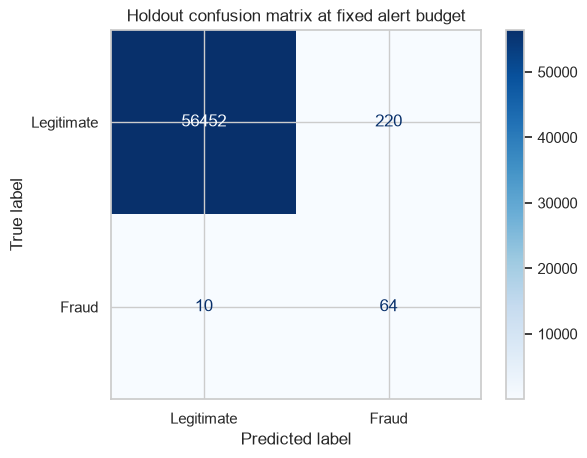

In [ ]:
model_key = 'rf_smote'
budget_fraction = 0.005
score = pred[f'score_{model_key}'].to_numpy()
k = max(1, math.ceil(len(pred) * budget_fraction))
flagged = score >= sorted(score, reverse=True)[k-1]
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_true, flagged, labels=[0,1])
print(f'Model={score_names[model_key]}, review budget={100*budget_fraction:.2f}%, alerts={k}')
ConfusionMatrixDisplay(cm, display_labels=['Legitimate','Fraud']).plot(cmap='Blues', values_format='d'); 
plt.title('Holdout confusion matrix at fixed alert budget'); 
plt.show()

## Feature importance and limits

Random Forest feature importance indicates reliance within this fitted model. It does not explain why a specific transaction is fraudulent, establish causality, or decode V1-V28.

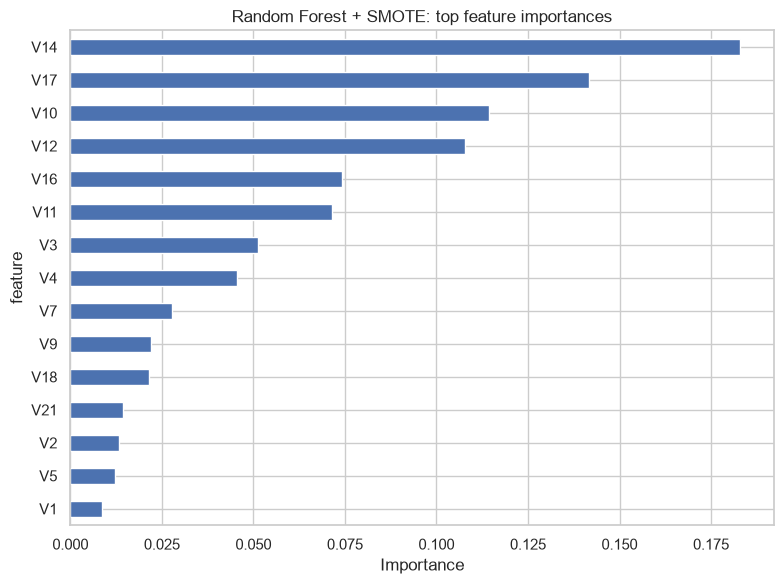

In [18]:
fi_path = ROOT/'reports/feature_importance.csv'
if fi_path.exists():
    fi = pd.read_csv(fi_path).head(15).sort_values('importance')
    fi.plot(kind='barh', x='feature', y='importance', legend=False, figsize=(8,6), title='Random Forest + SMOTE: top feature importances')
    plt.xlabel('Importance'); plt.tight_layout(); plt.show()